<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Seminars/S11_face_features_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path

from sklearn.datasets import fetch_olivetti_faces


DATA_HOME = "data_cache"



faces = fetch_olivetti_faces(data_home=str(DATA_HOME), download_if_missing=True)
assert faces.images.shape == (400, 64, 64)
assert faces.target.shape == (400,)
cached = fetch_olivetti_faces(data_home=str(DATA_HOME), download_if_missing=False)
assert cached.images.shape == faces.images.shape
print(f"Кэш готов: {DATA_HOME}")
print("Проверка без загрузки из сети: 400 портретов, 40 человек.")




downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to data_cache
Кэш готов: data_cache
Проверка без загрузки из сети: 400 портретов, 40 человек.


# Чем лучше описать лицо? Olivetti Faces

**Одна задача:** определить, кто из 40 *известных* людей изображён на готовом портрете. У каждого человека есть фотографии в обучении и проверке. Мы сравним исходные пиксели, координаты PCA («собственные лица», eigenfaces) и фиксированные признаки Хаара при одном классификаторе `KNeighborsClassifier`.

План: одно разбиение 6/2/2 снимка на человека → выбор `k` и числа компонент на validation → **однократная** оценка выбранных моделей на test. `fit` для PCA и `StandardScaler` только на train. Здесь нет поиска лица на фотографии: изображения уже обрезаны. Подробнее о [наборе Olivetti Faces](https://scikit-learn.org/stable/datasets/real_world.html#the-olivetti-faces-dataset) и [риске утечки данных](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


## 0. Подготовка и данные

Если кэш отсутствует, заранее выполните `python prepare_data.py` при доступном интернете (см. README). Во время семинара загрузка ниже не обращается к сети.


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
DATA_HOME = Path.cwd() / "data_cache"


In [ ]:
faces = fetch_olivetti_faces(data_home=str(DATA_HOME), download_if_missing=False)
X, images, y = faces.data, faces.images, faces.target
assert X.shape == (400, 4096) and images.shape == (400, 64, 64)
assert np.array_equal(np.bincount(y), np.repeat(10, 40))
print("data:", X.shape, "images:", images.shape, "target:", y.shape)
print("Классов:", len(np.unique(y)), "; яркость:", (X.min(), X.max()))


data: (400, 4096) images: (400, 64, 64) target: (400,)
Классов: 40 ; яркость: (np.float32(0.0), np.float32(1.0))


`images` хранит матрицы 64 × 64 для показа, `data` — те же портреты в виде 4096 пикселей; `target` — номер человека от 0 до 39. Посмотрим вариации внутри трёх классов.


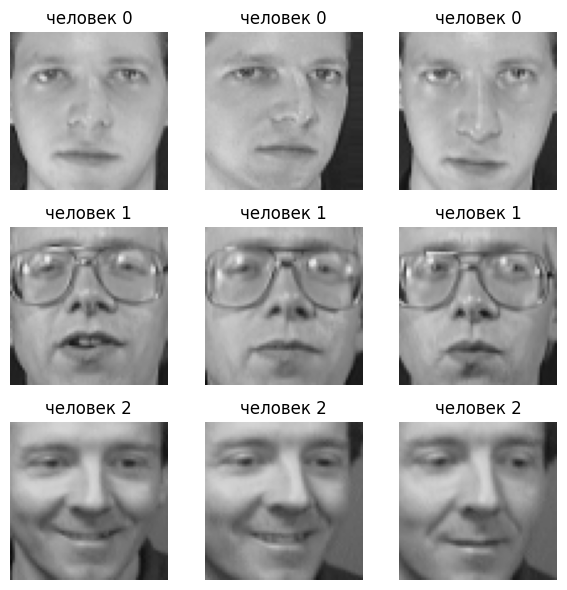

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for row, person in enumerate([0, 1, 2]):
    for col, idx in enumerate(np.flatnonzero(y == person)[:3]):
        axes[row, col].imshow(images[idx], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"человек {person}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()


**Остановка 1.** Что меняется между снимками одного человека? Почему близость по пикселям может обмануть kNN?


## 1. Один протокол разбиения

Разбейте **индексы**, затем используйте их во всех трёх опытах. Сначала отделите 40% каждого класса; остаток разделите пополам. Каждый вызов `train_test_split` должен быть стратифицированным и иметь `random_state=SEED`. Не обучайте преобразования до разбиения.


In [ ]:
idx_all = np.arange(len(y))
idx_train, idx_holdout = train_test_split(idx_all, test_size=0.4, stratify=y)
idx_val, idx_test = train_test_split(idx_holdout, test_size=0.5, stratify=y[idx_holdout])
# TODO 1: получите idx_train и idx_holdout (60% / 40%; stratify=y).
# TODO 2: разделите idx_holdout на idx_val и idx_test пополам,
#         стратифицируя по y[idx_holdout].
#raise NotImplementedError("Заполните два шага стратифицированного разбиения")


In [ ]:
X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
assert (len(idx_train), len(idx_val), len(idx_test)) == (240, 80, 80)
assert all(np.array_equal(np.bincount(part, minlength=40), np.repeat(n, 40))
           for part, n in [(y_train, 6), (y_val, 2), (y_test, 2)])
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0
print("Размеры train/validation/test:", X_train.shape, X_val.shape, X_test.shape)


Размеры train/validation/test: (240, 4096) (80, 4096) (80, 4096)


**Остановка 2.** Сейчас test существует, но его метки до выбора параметров использовать нельзя. Какие операции вправе видеть validation, а какие — только train?


## 2. Точка отсчёта: исходные пиксели

Метрики: `accuracy` — доля верных ответов, `macro-F1` — среднее F1 по 40 классам с равным весом. Выбор для всех методов одинаков: максимум **macro-F1** на validation, затем accuracy; при равенстве — меньше компонент и меньше `k`. Сверьте смысл метрик с [документацией scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).


In [ ]:
K_VALUES = (1, 3, 5)
COMPONENTS = (20, 50, 100)

def scores(y_true, y_pred):
    acc = accuracy_score(y_true=y_true, y_pred=y_pred)
    f1 = f1_score(y_true=y_true, y_pred=y_pred, average="macro")
    return {"accuracy": acc, "macro_f1": f1}
    # TODO 3: верните словарь с ключами "accuracy" и "macro_f1".
    # Подсказка: accuracy_score(...), f1_score(..., average="macro").
    raise NotImplementedError("Посчитайте две метрики")


In [ ]:
def show_validation(rows):
    for row in rows:
        print(row.get("n_components", "—"), row["k"],
              f'{row["accuracy"]:.3f}', f'{row["macro_f1"]:.3f}')

def pick_best(rows):
    return max(rows, key=lambda r: (r["macro_f1"], r["accuracy"],
                                     -r.get("n_components", 0), -r["k"]))


In [ ]:
pixel_rows = []
for k in K_VALUES:
    classifier = KNeighborsClassifier(n_neighbors=k)
    classifier.fit(X_train, y_train)
    pred_val = classifier.predict(X_val)
    # TODO 4: создайте KNeighborsClassifier(n_neighbors=k),
    # обучите на X_train, y_train и предскажите метки X_val.
    # raise NotImplementedError("Обучите kNN на пикселях")
    pixel_rows.append({"k": k, **scores(y_val, pred_val)})
show_validation(pixel_rows)


— 1 0.838 0.806
— 3 0.762 0.748
— 5 0.675 0.658


In [ ]:
pixel_best = pick_best(pixel_rows)
print("Пиксели, выбранный вариант:", pixel_best)


Пиксели, выбранный вариант: {'k': 1, 'accuracy': 0.8375, 'macro_f1': 0.8058333333333334}


**Остановка 3.** Почему `k=1` может ошибаться на изменении света или ракурса? Сравните две метрики; test пока закрыт.


## 3. Собственные лица (eigenfaces / PCA)

PCA вычитает **среднее обучающее лицо** и ищет направления наибольшей вариации; координаты по этим направлениям заменяют 4096 пикселей. `fit_transform` примените только к train, `transform` — к validation. Одну PCA с 100 компонентами обучаем на train, затем сравниваем первые 20/50/100 координат. Это небольшой перебор из плана, а не поиск по test. См. [исходную работу Turk и Pentland](https://www.cs.utexas.edu/~grauman/courses/spring2007/395T/papers/turk_pentland_1991.pdf), [API PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) и [пример eigenfaces](https://scikit-learn.org/stable/auto_examples/applications/plot_face_recognition.html).


In [ ]:
pca = PCA(n_components=max(COMPONENTS), svd_solver="randomized", random_state=SEED)
pca.fit(X_train)
Z_train = pca.transform(X_train)
Z_val = pca.transform(X_val)
# TODO 5: обучите pca только на X_train и получите Z_train;
# получите Z_val через pca.transform(X_val), без fit на validation.
#raise NotImplementedError("Обучите PCA только на train")
assert Z_train.shape == (240, 100) and Z_val.shape == (80, 100)


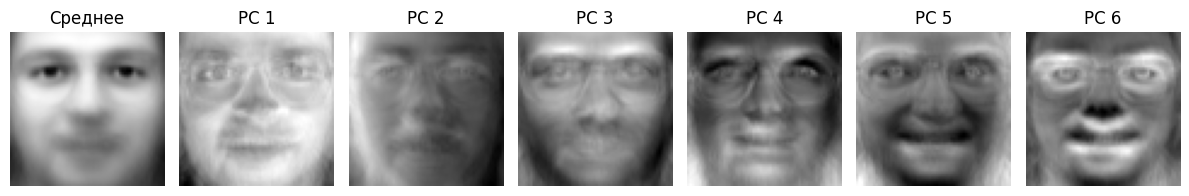

In [ ]:
fig, axes = plt.subplots(1, 7, figsize=(12, 2.3))
axes[0].imshow(pca.mean_.reshape(64, 64), cmap="gray")
axes[0].set_title("Среднее")
for i in range(6):
    axes[i + 1].imshow(pca.components_[i].reshape(64, 64), cmap="gray")
    axes[i + 1].set_title(f"PC {i + 1}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()


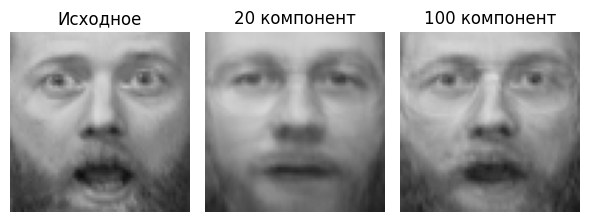

In [ ]:
z_one = pca.transform(X_train[:1])
fig, axes = plt.subplots(1, 3, figsize=(6, 2.3))
axes[0].imshow(X_train[0].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Исходное")
for ax, n in zip(axes[1:], (20, 100)):
    z_cut = z_one.copy(); z_cut[:, n:] = 0
    ax.imshow(pca.inverse_transform(z_cut)[0].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{n} компонент")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()


**Остановка 4.** Компонента PCA похожа на лицо, но является направлением изменений яркости. Почему больше объяснённой дисперсии ещё не обещает лучшую идентификацию?


In [ ]:
pca_rows = []
for n in COMPONENTS:
    for k in K_VALUES:
        classifier_pca_n = KNeighborsClassifier(n_neighbors=k)
        classifier_pca_n.fit(Z_train[:, :n], y_train)
        pred_val = classifier_pca_n.predict(Z_val[:, :n])
        pca_rows.append({"k": k, "n_components": n, **scores(y_val, pred_val)})
        # TODO 6: обучите тот же kNN на первых n столбцах Z_train;
        # предскажите Z_val[:, :n] и запишите n, k, обе метрики.
        #raise NotImplementedError("Сравните 9 сочетаний PCA и kNN")
show_validation(pca_rows)


20 1 0.838 0.812
20 3 0.775 0.739
20 5 0.650 0.621
50 1 0.825 0.797
50 3 0.800 0.781
50 5 0.662 0.643
100 1 0.838 0.806
100 3 0.787 0.768
100 5 0.662 0.638


In [ ]:
pca_best = pick_best(pca_rows)
print("PCA, выбранный вариант:", pca_best)
print("Объяснённая дисперсия для выбранной размерности:",
      round(pca.explained_variance_ratio_[:pca_best["n_components"]].sum(), 3))


PCA, выбранный вариант: {'k': 1, 'n_components': 20, 'accuracy': 0.8375, 'macro_f1': 0.8125}
Объяснённая дисперсия для выбранной размерности: 0.772


## 4. Фиксированные признаки Хаара

Признак — разность **средних яркостей** соседних половин окна: `(сумма слева − сумма справа) / площадь половины`. Аналогично для верха и низа. Сумма прямоугольника берётся из четырёх углов интегрального изображения. В лекции признаки Хаара вместе с бустингом и каскадом относились к **детекции**; здесь берём только фиксированные признаки уже обрезанных лиц и проверяем **идентификацию**. Это не обучение детектора Виолы — Джонса. См. [статью Viola и Jones](https://www.cs.columbia.edu/~jebara/4995/papers/violaJones_CVPR2001.pdf) и [пример интегрального изображения в scikit-image](https://scikit-image.org/docs/stable/auto_examples/applications/plot_haar_extraction_selection_classification.html).


In [ ]:
mini = np.array([[1, 1, 3, 3],
                 [1, 2, 4, 4],
                 [2, 2, 5, 5],
                 [2, 2, 6, 6]])
I = np.pad(mini.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))
print("Пиксели:\n", mini)
print("Интегральное изображение с нулевой рамкой:\n", I)


Пиксели:
 [[1 1 3 3]
 [1 2 4 4]
 [2 2 5 5]
 [2 2 6 6]]
Интегральное изображение с нулевой рамкой:
 [[ 0  0  0  0  0]
 [ 0  1  2  5  8]
 [ 0  2  5 12 19]
 [ 0  4  9 21 33]
 [ 0  6 13 31 49]]


In [ ]:
# TODO 7: по четырём углам I вычислите суммы прямоугольников
# [строки 0:4, столбцы 0:2] и [строки 0:4, столбцы 2:4].
# Затем найдите (left - right) / 8. Не суммируйте mini напрямую.
left = I[4, 2]
right = I[4,4] - I[4, 2]
haar_one = (left - right) / 8
#raise NotImplementedError("Вычислите один признак по интегральному изображению")
assert np.isclose(haar_one, (mini[:, :2].sum() - mini[:, 2:].sum()) / 8)
print("Левая сумма:", left, "; правая:", right, "; признак:", haar_one)


Левая сумма: 13 ; правая: 36 ; признак: -2.875


**Остановка 5.** Нулевая рамка делает формулу прямоугольника единообразной: `I[y1,x1] - I[y0,x1] - I[y1,x0] + I[y0,x0]`. Почему площадь половины равна 8?


Готовая функция ниже технически длинная. Она **ничего не обучает**: для каждого портрета берёт одинаковые окна 16 × 16 с шагом 8 и 32 × 32 с шагом 16; в каждом окне считает левую/правую и верхнюю/нижнюю разности. Получается `(7×7 + 3×3)×2 = 116` признаков. См. также [API Haar-like признаков scikit-image](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.haar_like_feature).


In [ ]:
def extract_fixed_haar(batch):
    assert batch.ndim == 3 and batch.shape[1:] == (64, 64)
    ii = np.pad(batch.cumsum(1).cumsum(2), ((0, 0), (1, 0), (1, 0)))
    def area(y0, x0, y1, x1):
        return ii[:, y1, x1] - ii[:, y0, x1] - ii[:, y1, x0] + ii[:, y0, x0]
    columns = []
    for size, step in ((16, 8), (32, 16)):
        half = size // 2
        for y0 in range(0, 65 - size, step):
            for x0 in range(0, 65 - size, step):
                y1, x1 = y0 + size, x0 + size
                left = area(y0, x0, y1, x0 + half)
                right = area(y0, x0 + half, y1, x1)
                top = area(y0, x0, y0 + half, x1)
                bottom = area(y0 + half, x0, y1, x1)
                columns += [(left - right) / (size * half),
                            (top - bottom) / (size * half)]
    return np.column_stack(columns).astype(np.float32)


In [ ]:
haar_all = extract_fixed_haar(images)
assert haar_all.shape == (400, 116)
print("Фиксированные признаки:", haar_all.shape)


Фиксированные признаки: (400, 116)


In [ ]:
H_train, H_val = haar_all[idx_train], haar_all[idx_val]
scaler = StandardScaler()
scaler.fit(H_train)
H_train_scaled = scaler.transform(H_train)
H_val_scaled = scaler.transform(H_val)
# TODO 8: scaler.fit_transform только для H_train;
# H_val преобразуйте через scaler.transform без fit.
# raise NotImplementedError("Масштабируйте признаки только по train")
assert H_train_scaled.shape == (240, 116) and H_val_scaled.shape == (80, 116)


In [ ]:
haar_rows = []
for k in K_VALUES:
    classifier_scaled = KNeighborsClassifier(n_neighbors=k)
    classifier_scaled.fit(H_train_scaled, y_train)
    pred_val = classifier_scaled.predict(H_val_scaled)
    haar_rows.append({"k": k, **scores(y_val, pred_val)})
    # TODO 9: обучите kNN на H_train_scaled, предскажите H_val_scaled;
    # добавьте k и обе validation-метрики в haar_rows.
    # raise NotImplementedError("Оцените признаки Хаара на validation")
show_validation(haar_rows)


— 1 0.863 0.835
— 3 0.787 0.758
— 5 0.713 0.655


In [ ]:
haar_best = pick_best(haar_rows)
print("Хаар, выбранный вариант:", haar_best)


Хаар, выбранный вариант: {'k': 1, 'accuracy': 0.8625, 'macro_f1': 0.835}


**Остановка 6.** Почему стандартное отклонение для каждого признака оценивается только на train? Что изменится, если сделать `fit` по всем 400 портретам?


## 5. Один выход на test

Параметры уже зафиксированы по validation. Сейчас **один раз** преобразуем test и получим предсказания трёх выбранных моделей. Модели обучаем на том же train, не подмешивая validation. После просмотра test больше ничего не подбираем.


In [ ]:
print("Пиксели:", pixel_best)
print("PCA:", pca_best)
print("Хаар:", haar_best)


Пиксели: {'k': 1, 'accuracy': 0.8375, 'macro_f1': 0.8058333333333334}
PCA: {'k': 1, 'n_components': 20, 'accuracy': 0.8375, 'macro_f1': 0.8125}
Хаар: {'k': 1, 'accuracy': 0.8625, 'macro_f1': 0.835}


In [ ]:
train_features = {
    "Пиксели": X_train,
    "Eigenfaces/PCA": Z_train[:, :pca_best["n_components"]],
    "Haar-like": H_train_scaled,
}
test_features = {
    "Пиксели": X_test,
    "Eigenfaces/PCA": pca.transform(X_test)[:, :pca_best["n_components"]],
    "Haar-like": scaler.transform(haar_all[idx_test]),
}
chosen_k = {"Пиксели": pixel_best["k"],
            "Eigenfaces/PCA": pca_best["k"], "Haar-like": haar_best["k"]}


In [ ]:
predictions = {}
for name in train_features:
    classifier_test = KNeighborsClassifier(n_neighbors=chosen_k[name])
    classifier_test.fit(train_features[name], y_train)
    pred_test = classifier_test.predict(test_features[name])
    predictions[name] = pred_test
    # TODO 10: обучите KNeighborsClassifier с выбранным k на train_features[name],
    # предскажите test_features[name], сохраните в predictions[name].
    #raise NotImplementedError("Получите test-предсказания выбранных моделей")


In [ ]:
test_rows = []
for name, pred in predictions.items():
    test_rows.append({"name": name,
                      "features": train_features[name].shape[1],
                      "k": k,
                      **scores(pred, pred_test)})
    # TODO 11: добавьте строку: представление, число признаков,
    # выбранное k, accuracy и macro-F1 на y_test.
    #raise NotImplementedError("Составьте итоговую таблицу")
print("Представление       признаков  k  accuracy  macro-F1")
for row in test_rows:
    print(f'{row["name"]:18} {row["features"]:10} {row["k"]:2} '
          f'{row["accuracy"]:9.3f} {row["macro_f1"]:9.3f}')


Представление       признаков  k  accuracy  macro-F1
Пиксели                  4096  5     0.912     0.909
Eigenfaces/PCA             20  5     0.887     0.876
Haar-like                 116  5     1.000     1.000


**Остановка 7.** Различия оцениваем на 80 test-снимках: два на каждого человека. Числа не следует выдавать за устойчивую оценку на любых камерах и людях. Посмотрим конкретные ошибки.


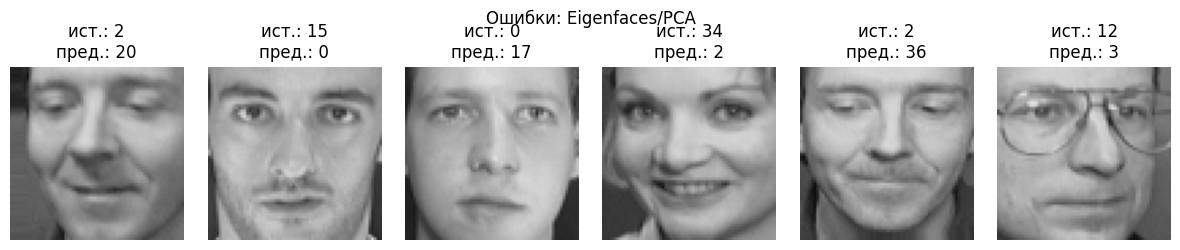

In [ ]:
error_name = max(predictions, key=lambda name: np.sum(predictions[name] != y_test))
error_pos = np.flatnonzero(predictions[error_name] != y_test)[:6]
fig, axes = plt.subplots(1, max(1, len(error_pos)), figsize=(2 * max(1, len(error_pos)), 2.5))
for ax, pos in zip(np.atleast_1d(axes), error_pos):
    ax.imshow(images[idx_test[pos]], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"ист.: {y_test[pos]}\nпред.: {predictions[error_name][pos]}")
    ax.axis("off")
if len(error_pos) == 0:
    axes.text(0.5, 0.5, "Ошибок нет", ha="center")
    axes.axis("off")
plt.suptitle(f"Ошибки: {error_name}")
plt.tight_layout()
plt.show()


## 6. Вывод — 3–5 предложений

**TODO 12.** Заполните после таблицы и просмотра снимков:

1. Какое представление оказалось сильнее на test и насколько? Совпадает ли порядок с validation?
2. Какие возможные причины видны у 1–2 ошибок: свет, ракурс, мимика, очки? Это гипотезы по снимкам, не доказательство.
3. Почему локальные признаки Хаара подходят для быстрого поиска лица в каскаде, но здесь могут уступить PCA при различении людей? Почему большая дисперсия PCA не гарантирует качество классификации?

**Общее обсуждение.** В схеме «найти лицо → распознать известного человека» какой шаг уже был сделан за нас?
